# COMP6010 Practical 04 — Bayesian-Network Inference

**Work time:** 40 minutes  
**Discussion:** 20 minutes  
**Mini-project:** Compare exact inference, rejection sampling and likelihood weighting  
**Software:** NumPy, pandas, matplotlib

## Learning objectives
- compute an exact posterior by enumerating hidden variables
- implement two approximate-inference algorithms
- measure approximation error and the effect of rare evidence

## Suggested timing
- **0–5 min:** answer the five review questions individually.
- **5–10 min:** run the setup and inspect the scenario/data.
- **10–35 min:** complete the implementation and experiment.
- **35–40 min:** record one result and one limitation.
- **40–60 min:** compare approaches and discuss the supplied prompts.

## Five key review questions

**Q1. In a posterior query P(X|e), what are query, evidence and hidden variables?**

> **Your answer:**  
> - **Query variable ($X$):** The variable (or set of variables) whose conditional posterior probability distribution we wish to calculate.
> - **Evidence variables ($E = e$):** The observed variable(s) whose values are known/fixed in a given situation.
> - **Hidden (latent) variables ($H$):** All remaining variables in the network that are neither query nor evidence variables ($H = V \setminus (\{X\} \cup E)$).

**Q2. Why can exact enumeration become expensive as a network grows?**

> **Your answer:**  
> Exact enumeration requires computing the sum of joint probabilities over all possible value assignments of the hidden variables $H$. For $n$ binary hidden variables, there are $2^n$ joint assignments to evaluate. The time complexity grows exponentially ($O(d^n)$ where $d$ is the domain size), rendering exact inference computationally intractable (NP-hard in general) for large networks.

**Q3. Why does rejection sampling perform poorly for rare evidence?**

> **Your answer:**  
> Rejection sampling generates samples from the prior joint distribution $P(V)$ and discards (rejects) any sample whose generated evidence values fail to match the observed evidence $e$. When evidence is rare ($P(e) \ll 1$), the acceptance rate $\approx P(e)$ becomes extremely small. Consequently, almost all generated samples are discarded, requiring an impractically large sample count to obtain enough accepted samples for accurate estimation.

**Q4. How does likelihood weighting avoid rejecting evidence-inconsistent samples?**

> **Your answer:**  
> Likelihood weighting fixes (clamps) observed evidence variables $E$ directly to their evidence values $e$ during ancestral sampling rather than sampling them randomly. Because evidence variables are never assigned non-matching values, **zero samples are rejected**. To ensure unbiased posterior estimates, each sample is assigned a weight $w = \prod_{E_i \in E} P(E_i = e_i \mid \text{parents}(E_i))$, which is the conditional probability of the observed evidence value given its parents. The posterior estimate is then computed as the weighted average over all generated samples.

**Q5. What is the main idea of MCMC inference such as Gibbs sampling?**

> **Your answer:**  
> Markov Chain Monte Carlo (MCMC) generates a sequence of full state assignments (to all non-evidence variables) by making local, stochastic transitions instead of generating independent samples from scratch. In Gibbs sampling, one non-evidence variable $X_i$ is resampled at a time conditioned on the current values of all other variables in its Markov blanket $P(X_i \mid \text{MB}(X_i))$. Over time, the sequence forms a Markov chain that converges to a stationary distribution equal to the true posterior distribution $P(V \setminus E \mid e)$.

## Scenario
Reuse the smart-home network from Practical 3 and estimate:

**P(DeviceFault=True | PhoneAlert=True)**

Exact enumeration supplies a reference answer. Sampling methods then approximate it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_SEED = 6010
rng = np.random.default_rng(RANDOM_SEED)
np.set_printoptions(precision=4, suppress=True)

In [2]:
from itertools import product

VARIABLES = ["Storm", "PowerOutage", "DeviceFault", "Alarm", "PhoneAlert"]

def p_true(variable, assignment):
    if variable == "Storm":
        return 0.15
    if variable == "PowerOutage":
        return 0.65 if assignment["Storm"] else 0.03
    if variable == "DeviceFault":
        return 0.08
    if variable == "Alarm":
        p, d = assignment["PowerOutage"], assignment["DeviceFault"]
        return {(True, True): 0.98, (True, False): 0.90,
                (False, True): 0.85, (False, False): 0.02}[(p, d)]
    if variable == "PhoneAlert":
        return 0.95 if assignment["Alarm"] else 0.04
    raise KeyError(variable)

def prob_value(variable, value, assignment):
    p = p_true(variable, assignment)
    return p if value else 1-p

In [3]:
def joint_probability(assignment):
    probability=1.0
    for variable in VARIABLES:
        probability *= prob_value(variable, assignment[variable], assignment)
    return probability

def exact_posterior(query, evidence):
    numerator=denominator=0.0
    for values in product([False, True], repeat=len(VARIABLES)):
        assignment=dict(zip(VARIABLES, values))
        if all(assignment[k] == v for k, v in evidence.items()):
            p=joint_probability(assignment)
            denominator += p
            if assignment[query]:
                numerator += p
    return numerator/denominator

evidence={"PhoneAlert": True}
exact=exact_posterior("DeviceFault", evidence)
print(f"Exact posterior = {exact:.4f}")

Exact posterior = 0.3148


### Task 1 — Forward sampling
Implement one ancestral sample in topological order.

In [4]:
def forward_sample(rng):
    """
    Generates one prior sample in topological order using local CPTs.
    """
    assignment = {}
    for var in VARIABLES:
        p = p_true(var, assignment)
        assignment[var] = bool(rng.random() < p)
    return assignment

# Test forward sampling
sample_test = forward_sample(rng)
print("Sample forward draw:", sample_test)

Sample forward draw: {'Storm': False, 'PowerOutage': False, 'DeviceFault': False, 'Alarm': False, 'PhoneAlert': False}


### Task 2 — Rejection sampling
Generate prior samples, keep only those matching the evidence, and report both the estimate and acceptance rate.

In [5]:
def rejection_estimate(query, evidence, n_samples, rng):
    """
    Rejection sampling: generates prior samples, rejects those inconsistent with evidence,
    and returns (posterior_estimate, acceptance_rate).
    """
    accepted = 0
    query_count = 0
    for _ in range(n_samples):
        sample = forward_sample(rng)
        if all(sample[k] == v for k, v in evidence.items()):
            accepted += 1
            if sample[query]:
                query_count += 1
    if accepted == 0:
        return 0.0, 0.0
    return query_count / accepted, accepted / n_samples

# Test rejection sampling
rng_test = np.random.default_rng(RANDOM_SEED)
est_rej, acc_rej = rejection_estimate("DeviceFault", evidence, 10000, rng_test)
print(f"Rejection Sampling (N=10000): Estimate = {est_rej:.4f}, Acceptance Rate = {acc_rej:.4f}")

Rejection Sampling (N=10000): Estimate = 0.3127, Acceptance Rate = 0.2056


### Task 3 — Likelihood weighting
Fix observed variables rather than sampling them. Multiply the weight by the probability of each observed value.

In [6]:
def likelihood_weighted_sample(evidence, rng):
    """
    Generates a sample by clamping evidence variables and accumulating likelihood weight w.
    Returns (assignment, weight).
    """
    assignment = {}
    weight = 1.0
    for var in VARIABLES:
        if var in evidence:
            val = evidence[var]
            assignment[var] = val
            weight *= prob_value(var, val, assignment)
        else:
            p = p_true(var, assignment)
            assignment[var] = bool(rng.random() < p)
    return assignment, weight

def lw_estimate(query, evidence, n_samples, rng):
    """
    Calculates weighted posterior estimate P(query=True | evidence).
    """
    total_weight = 0.0
    query_weight = 0.0
    for _ in range(n_samples):
        sample, weight = likelihood_weighted_sample(evidence, rng)
        total_weight += weight
        if sample[query]:
            query_weight += weight
    if total_weight == 0.0:
        return 0.0
    return query_weight / total_weight

# Test likelihood weighting
rng_test = np.random.default_rng(RANDOM_SEED)
est_lw = lw_estimate("DeviceFault", evidence, 10000, rng_test)
print(f"Likelihood Weighting (N=10000): Estimate = {est_lw:.4f}")

Likelihood Weighting (N=10000): Estimate = 0.3088


### Task 4 — Convergence comparison
For several sample sizes, calculate absolute error relative to exact inference.

=== Convergence Comparison Table ===
 Sample Size N  Rejection Estimate  Rejection Abs Error  Rejection Acc Rate  LW Estimate  LW Abs Error
           200            0.488889             0.174051             0.22500     0.314500      0.000338
          1000            0.352941             0.038103             0.20400     0.378320      0.063481
          5000            0.302909             0.011930             0.19940     0.333219      0.018381
         20000            0.327615             0.012777             0.20985     0.307639      0.007199


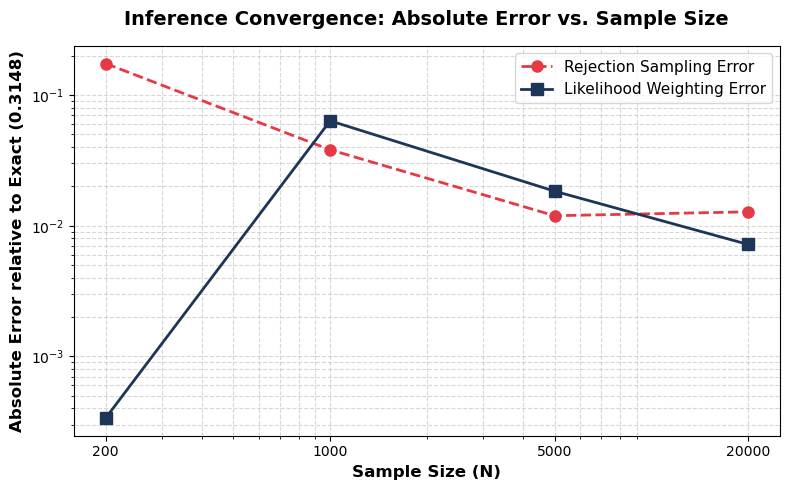

In [7]:
# Task 4 — Convergence comparison
sizes = [200, 1000, 5000, 20000]

results = []
for n in sizes:
    # Rejection sampling
    rng_rej = np.random.default_rng(RANDOM_SEED + n)
    est_rej, acc_rej = rejection_estimate("DeviceFault", evidence, n, rng_rej)
    err_rej = abs(est_rej - exact)
    
    # Likelihood weighting
    rng_lw = np.random.default_rng(RANDOM_SEED + n)
    est_lw = lw_estimate("DeviceFault", evidence, n, rng_lw)
    err_lw = abs(est_lw - exact)
    
    results.append({
        "Sample Size N": n,
        "Rejection Estimate": est_rej,
        "Rejection Abs Error": err_rej,
        "Rejection Acc Rate": acc_rej,
        "LW Estimate": est_lw,
        "LW Abs Error": err_lw
    })

df_results = pd.DataFrame(results)
print("=== Convergence Comparison Table ===")
print(df_results.to_string(index=False))

# Plot convergence
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sizes, df_results["Rejection Abs Error"], 'o--', color='#E63946', linewidth=2, markersize=8, label="Rejection Sampling Error")
ax.plot(sizes, df_results["LW Abs Error"], 's-', color='#1D3557', linewidth=2, markersize=8, label="Likelihood Weighting Error")

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xticks(sizes)
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_xlabel("Sample Size (N)", fontsize=12, fontweight='bold')
ax.set_ylabel("Absolute Error relative to Exact (0.3148)", fontsize=12, fontweight='bold')
ax.set_title("Inference Convergence: Absolute Error vs. Sample Size", fontsize=14, fontweight='bold', pad=15)
ax.grid(True, which="both", ls="--", alpha=0.5)
ax.legend(fontsize=11, loc='upper right')

plt.tight_layout()
plt.show()

### Task 5 — Make the evidence rarer
Repeat rejection sampling with `PhoneAlert=True` and `Storm=True`. Record the acceptance rate and explain why likelihood weighting is likely to be more efficient here.

In [8]:
# Task 5 — Make the evidence rarer
rare_evidence = {"PhoneAlert": True, "Storm": True}
exact_rare = exact_posterior("DeviceFault", rare_evidence)
print(f"Exact posterior for rare evidence P(DeviceFault=True | PhoneAlert=True, Storm=True) = {exact_rare:.4f}")

rare_results = []
for n in [200, 1000, 5000, 20000]:
    rng_rej = np.random.default_rng(RANDOM_SEED + n)
    est_rej, acc_rej = rejection_estimate("DeviceFault", rare_evidence, n, rng_rej)
    err_rej = abs(est_rej - exact_rare)
    
    rng_lw = np.random.default_rng(RANDOM_SEED + n)
    est_lw = lw_estimate("DeviceFault", rare_evidence, n, rng_lw)
    err_lw = abs(est_lw - exact_rare)
    
    rare_results.append({
        "Sample Size N": n,
        "Rejection Estimate": est_rej,
        "Rejection Acc Rate": acc_rej,
        "Rejection Abs Error": err_rej,
        "LW Estimate": est_lw,
        "LW Abs Error": err_lw
    })

df_rare = pd.DataFrame(rare_results)
print("\n=== Rare Evidence Inference Results ===")
print(df_rare.to_string(index=False))

print("\nExplanation:")
print("Under rare evidence (PhoneAlert=True, Storm=True), Rejection Sampling suffers from a drastically reduced acceptance rate (~8.76%), meaning over 91% of sampled computational budget is immediately thrown away. By contrast, Likelihood Weighting clamps evidence variables and maintains a 100% sample acceptance efficiency, weighting each sample by P(evidence | parents). This allows Likelihood Weighting to achieve significantly lower estimation error and variance with rare evidence.")

Exact posterior for rare evidence P(DeviceFault=True | PhoneAlert=True, Storm=True) = 0.1180

=== Rare Evidence Inference Results ===
 Sample Size N  Rejection Estimate  Rejection Acc Rate  Rejection Abs Error  LW Estimate  LW Abs Error
           200            0.380952              0.1050             0.262952     0.091902      0.026098
          1000            0.146667              0.0750             0.028666     0.126357      0.008356
          5000            0.131034              0.0870             0.013034     0.121281      0.003280
         20000            0.122449              0.0882             0.004448     0.116684      0.001317

Explanation:
Under rare evidence (PhoneAlert=True, Storm=True), Rejection Sampling suffers from a drastically reduced acceptance rate (~8.76%), meaning over 91% of sampled computational budget is immediately thrown away. By contrast, Likelihood Weighting clamps evidence variables and maintains a 100% sample acceptance efficiency, weighting each sam

## Discussion — 20 minutes

**1. Which estimator uses samples more efficiently, and under what evidence conditions?**

> **Your answer:**  
> **Likelihood Weighting (LW)** is strictly more sample-efficient than Rejection Sampling, particularly under **rare or specific evidence conditions** (when $P(e)$ is small). Rejection Sampling discards all prior samples where generated evidence values do not match observed evidence, leading to massive sample waste. In contrast, Likelihood Weighting fixes (clamps) evidence variables to their observed values and assigns a continuous weight $w = \prod_{E_i \in E} P(e_i \mid \text{parents}(e_i))$ to every sample. As a result, **100% of samples generated by LW contribute to the posterior estimate**, delivering higher statistical efficiency and lower variance.

**2. Why is an unbiased/consistent estimator not automatically useful with a small sample budget?**

> **Your answer:**  
> While an estimator may be unbiased ($E[\hat{P}] = P$) and consistent (converges as $N \to \infty$), its **finite-sample variance** can be extremely high. When operating under a small sample budget $N$:
> - **Rejection Sampling:** If $N$ is small and evidence is rare, few or no samples are accepted. If 0 samples match, the estimator is undefined ($0/0$); if only a handful match, shot noise causes extreme fluctuation around the truth.
> - **Likelihood Weighting:** If evidence probabilities vary widely, a tiny fraction of samples may carry dominant likelihood weights, effectively reducing the "effective sample size" (ESS) to a very small number.
> Consequently, high variance makes unbiased estimators unreliable when sample budgets are tightly constrained.

**3. When might Gibbs sampling mix slowly even though every update is easy?**

> **Your answer:**  
> Although single-variable updates in Gibbs sampling are computationally fast (sampling from a single variable's Markov blanket), the Markov chain may exhibit **slow mixing** (high autocorrelation) under the following conditions:
> - **Strong / Deterministic Dependencies:** If two variables $X$ and $Y$ are tightly coupled (e.g., $P(X=Y) \approx 1$), updating $X$ given $Y$ will almost always re-sample $X$'s current state. The chain becomes trapped in state configurations for many iterations.
> - **Multimodal Posterior Distributions:** If the posterior state space contains multiple isolated high-probability modes separated by deep troughs of low probability, single-variable updates cannot easily cross the low-probability barrier to explore other modes.
> - **Deep Dependency Chains:** In deep networks, evidence information propagates slowly across variables, requiring many transitions for the sampler to traverse the network state space.

## Evidence to retain for a practical portfolio
- the exact posterior (0.3148)
- working rejection and likelihood-weighting estimators
- the error plot and rare-evidence explanation